# 3.5 Nubes de palabras y bolsa de palabras (LEMATIZADO)

Este notebook toma `output/corpus_anfibia_limpio.csv` como corpus limpio y construye dos insumos para exploración y modelado posterior:

- nubes de palabras por categoría editorial;
- una representación bag of words por documento, guardada junto con atributos editoriales separados.

La matriz BoW se arma únicamente desde `document_text_final`. Los campos `tagline`, `autor_names`, `post_date`, `category` y `text_type` se preservan como atributos acompañantes, no como tokens del modelo.


## 1. Configuración


In [1]:
from pathlib import Path
import json
import re
import unicodedata
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Rutas estándar del proyecto
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "corpus_anfibia_lematizado.csv"
STOPWORDS_PATH = PROJECT_ROOT / "data" / "processed" / "stopwords_anfibia.txt"

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "topic_modeling_lematizado"
WORDCLOUD_DIR = PROJECT_ROOT / "outputs" / "wordclouds_by_category_lematizado"
TEMPORAL_WORDCLOUD_DIR = PROJECT_ROOT / "outputs" / "wordclouds_by_category_period"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
WORDCLOUD_DIR.mkdir(parents=True, exist_ok=True)
TEMPORAL_WORDCLOUD_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.exists(), f"Falta el archivo de entrada: {DATA_PATH.name}"
assert STOPWORDS_PATH.exists(), f"Falta el archivo de stopwords: {STOPWORDS_PATH.name}, ejecutar src/stopwords.py"

In [2]:
try:
    from wordcloud import WordCloud
    from PIL import ImageDraw, ImageFont
    WORDCLOUD_AVAILABLE = True
except ModuleNotFoundError:
    WORDCLOUD_AVAILABLE = False
    WordCloud = None
    ImageDraw = None
    ImageFont = None

if WORDCLOUD_AVAILABLE and not getattr(ImageDraw.ImageDraw.textbbox, "_wordcloud_truetype_compat", False):
    _original_textbbox = ImageDraw.ImageDraw.textbbox

    def _textbbox_truetype_compat(self, xy, text, font=None, *args, **kwargs):
        if isinstance(font, ImageFont.TransposedFont) and getattr(font, "orientation", None) is None:
            font = font.font
        return _original_textbbox(self, xy, text, font=font, *args, **kwargs)

    _textbbox_truetype_compat._wordcloud_truetype_compat = True
    ImageDraw.ImageDraw.textbbox = _textbbox_truetype_compat

FONT_CANDIDATES = [
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    "/usr/share/fonts/truetype/freefont/FreeSans.ttf",
    "/usr/share/fonts/truetype/ubuntu/Ubuntu-R.ttf",
    "/Library/Fonts/Arial.ttf",
    "C:/Windows/Fonts/arial.ttf",
]

WORDCLOUD_FONT_PATH = next((Path(path) for path in FONT_CANDIDATES if Path(path).exists()), None)
WORDCLOUD_AVAILABLE, WORDCLOUD_FONT_PATH


(True, WindowsPath('C:/Windows/Fonts/arial.ttf'))

## 2. Carga del corpus


In [3]:
TEXT_COLUMN = "document_text_final"
ATTRIBUTE_COLUMNS = ["tagline", "autor_names", "post_date", "category", "text_type"]
ID_COLUMNS = ["ID", "source_url", "title_text"]
USE_COLUMNS = ID_COLUMNS + ATTRIBUTE_COLUMNS + [TEXT_COLUMN]

df = pd.read_csv(DATA_PATH, usecols=USE_COLUMNS)

df[TEXT_COLUMN] = df[TEXT_COLUMN].fillna("").astype(str)
for col in ATTRIBUTE_COLUMNS:
    df[col] = df[col].fillna("").astype(str).str.strip()

df = df[df[TEXT_COLUMN].str.strip().ne("")].copy()
df = df.reset_index(drop=True)
df.insert(0, "doc_id", df.index)

df.shape


(3555, 10)

In [4]:
display(df[ID_COLUMNS + ATTRIBUTE_COLUMNS].head())
display(df["category"].value_counts().head(20).to_frame("documents"))


,ID,source_url,title_text,tagline,autor_names,post_date,category,text_type
0,15668,https://www.revistaanfibia.com/la-china-invisi...,La China invisible,Feria La Salada,Sebastián Hacher; Ariel Wilkis,2012-05-14 13:43:22,Política y Economía,Crónica
1,15706,https://www.revistaanfibia.com/grobocopatel-el...,El rico que se cree Steve Jobs,Gustavo Grobocopatel,Graciela Mochkofsky; Alexandre Roig,2012-05-24 13:36:12,Política y Economía,Crónica
2,15743,https://www.revistaanfibia.com/la-vaca-sagrada/,La vaca sagrada,,Josefina Licitra,2012-06-05 14:52:58,Tecnologías,
3,15695,https://www.revistaanfibia.com/los-arruinados-...,Los arruinados del Paraná,Adictos al juego,Gisele Sousa Dias,2012-06-14 10:16:11,Culturas,
4,15687,https://www.revistaanfibia.com/de-chile-tacna-...,De Chile a Tacna: una historia de carniceros y...,,Jorge Turpo Rivas,2012-06-25 14:52:05,Culturas,Crónica


,documents
category,
Política y Economía,1349
Culturas,985
Políticas de géneros,521
Otras,160
Salud,117
Ambiente,100
Tecnologías,98
Educación,75
Amor y sexo,51


## 3. Categorías normalizadas

Algunos documentos tienen más de una categoría. Se separan tanto valores con `;` como con `,`, y cada documento aporta a todas sus categorías.


In [5]:
def split_categories(value):
    parts = re.split(r"[;,]", str(value))
    return [part.strip() for part in parts if part.strip()]

category_rows = []
for doc_id, value in zip(df["doc_id"], df["category"]):
    categories = split_categories(value)
    if not categories:
        categories = ["Sin categoria"]
    for category in categories:
        category_rows.append({"doc_id": doc_id, "category_normalized": category})

categories_df = pd.DataFrame(category_rows)
category_counts = categories_df["category_normalized"].value_counts().rename_axis("category").reset_index(name="documents")

display(category_counts)


,category,documents
0,Política y Economía,1425
1,Culturas,1038
2,Políticas de géneros,539
3,Otras,164
4,Salud,126
5,Ambiente,113
6,Tecnologías,109
7,Educación,90
8,Amor y sexo,59


## 4. Stopwords y normalización

La lista combina stopwords frecuentes del español con términos editoriales o estructurales que no aportan mucho a las nubes ni a la matriz. 


In [6]:
with open(STOPWORDS_PATH, "r", encoding="utf-8") as f:
    STOPWORDS_LIST = f.read().splitlines()

STOPWORDS_SET = set(STOPWORDS_LIST)
print(f"Cargadas {len(STOPWORDS_LIST)} stopwords.")

def strip_accents(text):
    normalized = unicodedata.normalize("NFKD", str(text))
    return "".join(char for char in normalized if not unicodedata.combining(char))

def normalize_for_model(text):
    text = strip_accents(text).lower()
    text = re.sub(r"[^a-záéíóúüñ0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["text_for_model"] = df[TEXT_COLUMN].map(normalize_for_model)


Cargadas 442 stopwords.


## 5. Nube de palabras por categoría

Se genera un PNG por categoría en `output/topic_modeling/wordclouds_by_category/` y una grilla de previsualización con las categorías principales.


In [7]:
def slugify(value):
    value = strip_accents(value).lower()
    value = re.sub(r"[^a-z0-9]+", "-", value).strip("-")
    return value or "sin-categoria"

wordcloud_paths = []
if not WORDCLOUD_AVAILABLE:
    print("Falta instalar wordcloud. Ejecutá: python3 -m pip install wordcloud")
else:
    for category in category_counts["category"]:
        doc_ids = categories_df.loc[categories_df["category_normalized"].eq(category), "doc_id"]
        category_text = " ".join(df.loc[df["doc_id"].isin(doc_ids), "text_for_model"])
        if not category_text.strip():
            continue


        wc = WordCloud(
            width=1600,
            height=900,
            font_path=str(WORDCLOUD_FONT_PATH) if WORDCLOUD_FONT_PATH else None,
            background_color="white",
            stopwords=STOPWORDS_SET,
            max_words=180,
            collocations=False,
            prefer_horizontal=1.0,
            random_state=42,
            normalize_plurals=False,
        ).generate(category_text)

        # Dentro del loop de la sección 5:
        output_path = WORDCLOUD_DIR / f"wordcloud_{slugify(category)}.png"
        wc.to_file(output_path)
        wordcloud_paths.append({"category": category, "path": str(output_path.relative_to(PROJECT_ROOT))})

wordcloud_index = pd.DataFrame(wordcloud_paths, columns=["category", "path"])
wordcloud_index.to_csv(OUTPUT_DIR / "wordclouds_by_category_index.csv", index=False)
wordcloud_index


,category,path
0,Política y Economía,outputs\wordclouds_by_category_lematizado\word...
1,Culturas,outputs\wordclouds_by_category_lematizado\word...
2,Políticas de géneros,outputs\wordclouds_by_category_lematizado\word...
3,Otras,outputs\wordclouds_by_category_lematizado\word...
4,Salud,outputs\wordclouds_by_category_lematizado\word...
5,Ambiente,outputs\wordclouds_by_category_lematizado\word...
6,Tecnologías,outputs\wordclouds_by_category_lematizado\word...
7,Educación,outputs\wordclouds_by_category_lematizado\word...
8,Amor y sexo,outputs\wordclouds_by_category_lematizado\word...


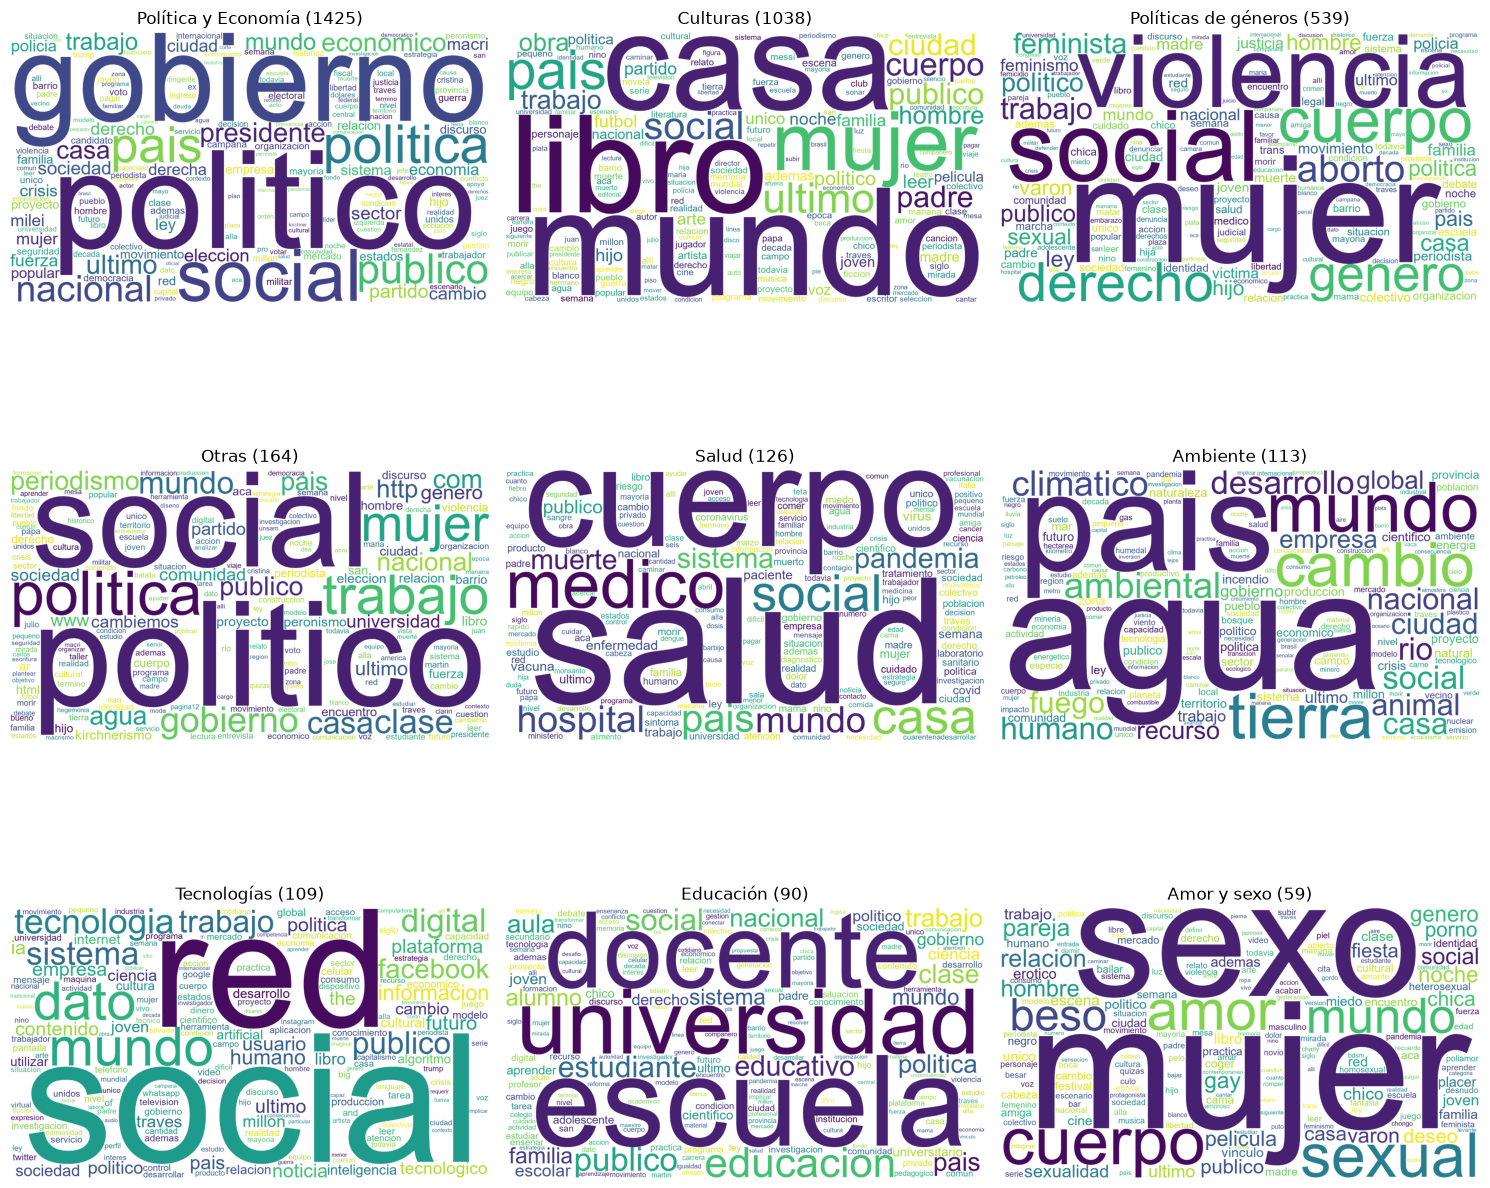

In [8]:
preview = wordcloud_index.merge(category_counts, left_on="category", right_on="category", how="left").head(12)

if preview.empty:
    print("No hay nubes para previsualizar todavía.")
else:
    n = len(preview)
    cols = 3
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4.8 * rows))
    axes = axes.flatten() if n > 1 else [axes]

    for ax, (_, row) in zip(axes, preview.iterrows()):
        image = plt.imread(PROJECT_ROOT / row["path"])
        ax.imshow(image)
        ax.set_title(f"{row['category']} ({row['documents']})")
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()



## 6. Nubes de palabras por categoría y temporalidad

Esta sección agrega una rutina para construir nubes por categoría y período, pero solo cuando hay suficiente evidencia textual. Cada ventana `categoría + período` se evalúa con tres criterios: cantidad mínima de documentos, cantidad mínima de tokens y cantidad mínima de términos únicos después de stopwords.

Por defecto se usa frecuencia anual (`TEMPORAL_FREQ = "Y"`). Para ventanas más densas se puede cambiar a trimestres (`"Q"`) o a años agrupados manualmente ajustando la columna `period` antes de llamar a la función.


In [9]:

TEMPORAL_WORDCLOUD_DIR = OUTPUT_DIR / "wordclouds_by_category_period"
TEMPORAL_WORDCLOUD_DIR.mkdir(parents=True, exist_ok=True)

TEMPORAL_FREQ = "Y"
MIN_DOCS_PER_CATEGORY_PERIOD = 20
MIN_TOKENS_PER_CATEGORY_PERIOD = 5_000
MIN_UNIQUE_TERMS_PER_CATEGORY_PERIOD = 80

df["post_date_dt"] = pd.to_datetime(df["post_date"], errors="coerce")

def count_valid_terms(text, stopwords):
    terms = [term for term in str(text).split() if term not in stopwords and len(term) >= 3]
    return len(terms), len(set(terms))

def make_category_period_frame(documents, category_membership, freq="Y"):
    base = documents[["doc_id", "post_date_dt", "text_for_model"]].copy()
    base = base.dropna(subset=["post_date_dt"])
    base["period"] = base["post_date_dt"].dt.to_period(freq).astype(str)
    return category_membership.merge(base, on="doc_id", how="inner")

def build_temporal_wordclouds_by_category(
    documents,
    category_membership,
    output_dir,
    freq="Y",
    min_docs=20,
    min_tokens=5_000,
    min_unique_terms=80,
    max_words=180,
):
    temporal_df = make_category_period_frame(documents, category_membership, freq=freq)
    records = []


    for (category, period), group in temporal_df.groupby(["category_normalized", "period"], sort=True):
        category_text = " ".join(group["text_for_model"])
        token_count, unique_terms = count_valid_terms(category_text, STOPWORDS_SET)
        doc_count = group["doc_id"].nunique()
        docs_ok = doc_count >= min_docs
        tokens_ok = token_count >= min_tokens
        unique_terms_ok = unique_terms >= min_unique_terms
        enough_statistics = docs_ok and tokens_ok and unique_terms_ok

        record = {
            "category": category,
            "period": period,
            "documents": int(doc_count),
            "tokens_after_stopwords": int(token_count),
            "unique_terms_after_stopwords": int(unique_terms),
            "docs_ok": bool(docs_ok),
            "tokens_ok": bool(tokens_ok),
            "unique_terms_ok": bool(unique_terms_ok),
            "enough_statistics": bool(enough_statistics),
            "path": "",
        }

        if WORDCLOUD_AVAILABLE and enough_statistics:
            wc = WordCloud(
                width=1600,
                height=900,
                font_path=str(WORDCLOUD_FONT_PATH) if WORDCLOUD_FONT_PATH else None,
                background_color="white",
                stopwords=STOPWORDS_SET,
                max_words=max_words,
                collocations=False,
                prefer_horizontal=1.0,
                random_state=42,
                normalize_plurals=False,
            ).generate(category_text)

            output_path = TEMPORAL_WORDCLOUD_DIR / f"wordcloud_{slugify(category)}_{slugify(period)}.png"
            wc.to_file(output_path)
            record["path"] = str(output_path.relative_to(PROJECT_ROOT))

        records.append(record)

    index = pd.DataFrame(records)
    if not index.empty:
        index = index.sort_values(["category", "period"]).reset_index(drop=True)
    return index

temporal_wordcloud_index = build_temporal_wordclouds_by_category(
    df,
    categories_df,
    TEMPORAL_WORDCLOUD_DIR,
    freq=TEMPORAL_FREQ,
    min_docs=MIN_DOCS_PER_CATEGORY_PERIOD,
    min_tokens=MIN_TOKENS_PER_CATEGORY_PERIOD,
    min_unique_terms=MIN_UNIQUE_TERMS_PER_CATEGORY_PERIOD,
)

temporal_wordcloud_index.to_csv(OUTPUT_DIR / "wordclouds_by_category_period_index.csv", index=False)

display(
    temporal_wordcloud_index["enough_statistics"]
    .value_counts(dropna=False)
    .rename_axis("enough_statistics")
    .reset_index(name="category_period_windows")
)

display(temporal_wordcloud_index.head(20))


,enough_statistics,category_period_windows
0,False,84
1,True,44


,category,period,documents,tokens_after_stopwords,unique_terms_after_stopwords,docs_ok,tokens_ok,unique_terms_ok,enough_statistics,path
0,Ambiente,2012,1,914,633,False,False,True,False,
1,Ambiente,2013,1,1417,927,False,False,True,False,
2,Ambiente,2014,1,1302,793,False,False,True,False,
3,Ambiente,2015,7,6032,3112,False,True,True,False,
4,Ambiente,2016,2,2080,1196,False,False,True,False,
5,Ambiente,2017,3,2164,1369,False,False,True,False,
6,Ambiente,2018,5,5286,2684,False,True,True,False,
7,Ambiente,2019,5,5523,2764,False,True,True,False,
8,Ambiente,2020,23,21082,6624,True,True,True,True,data\processed\topic_modeling_lematizado\wordc...
9,Ambiente,2021,22,20996,6622,True,True,True,True,data\processed\topic_modeling_lematizado\wordc...


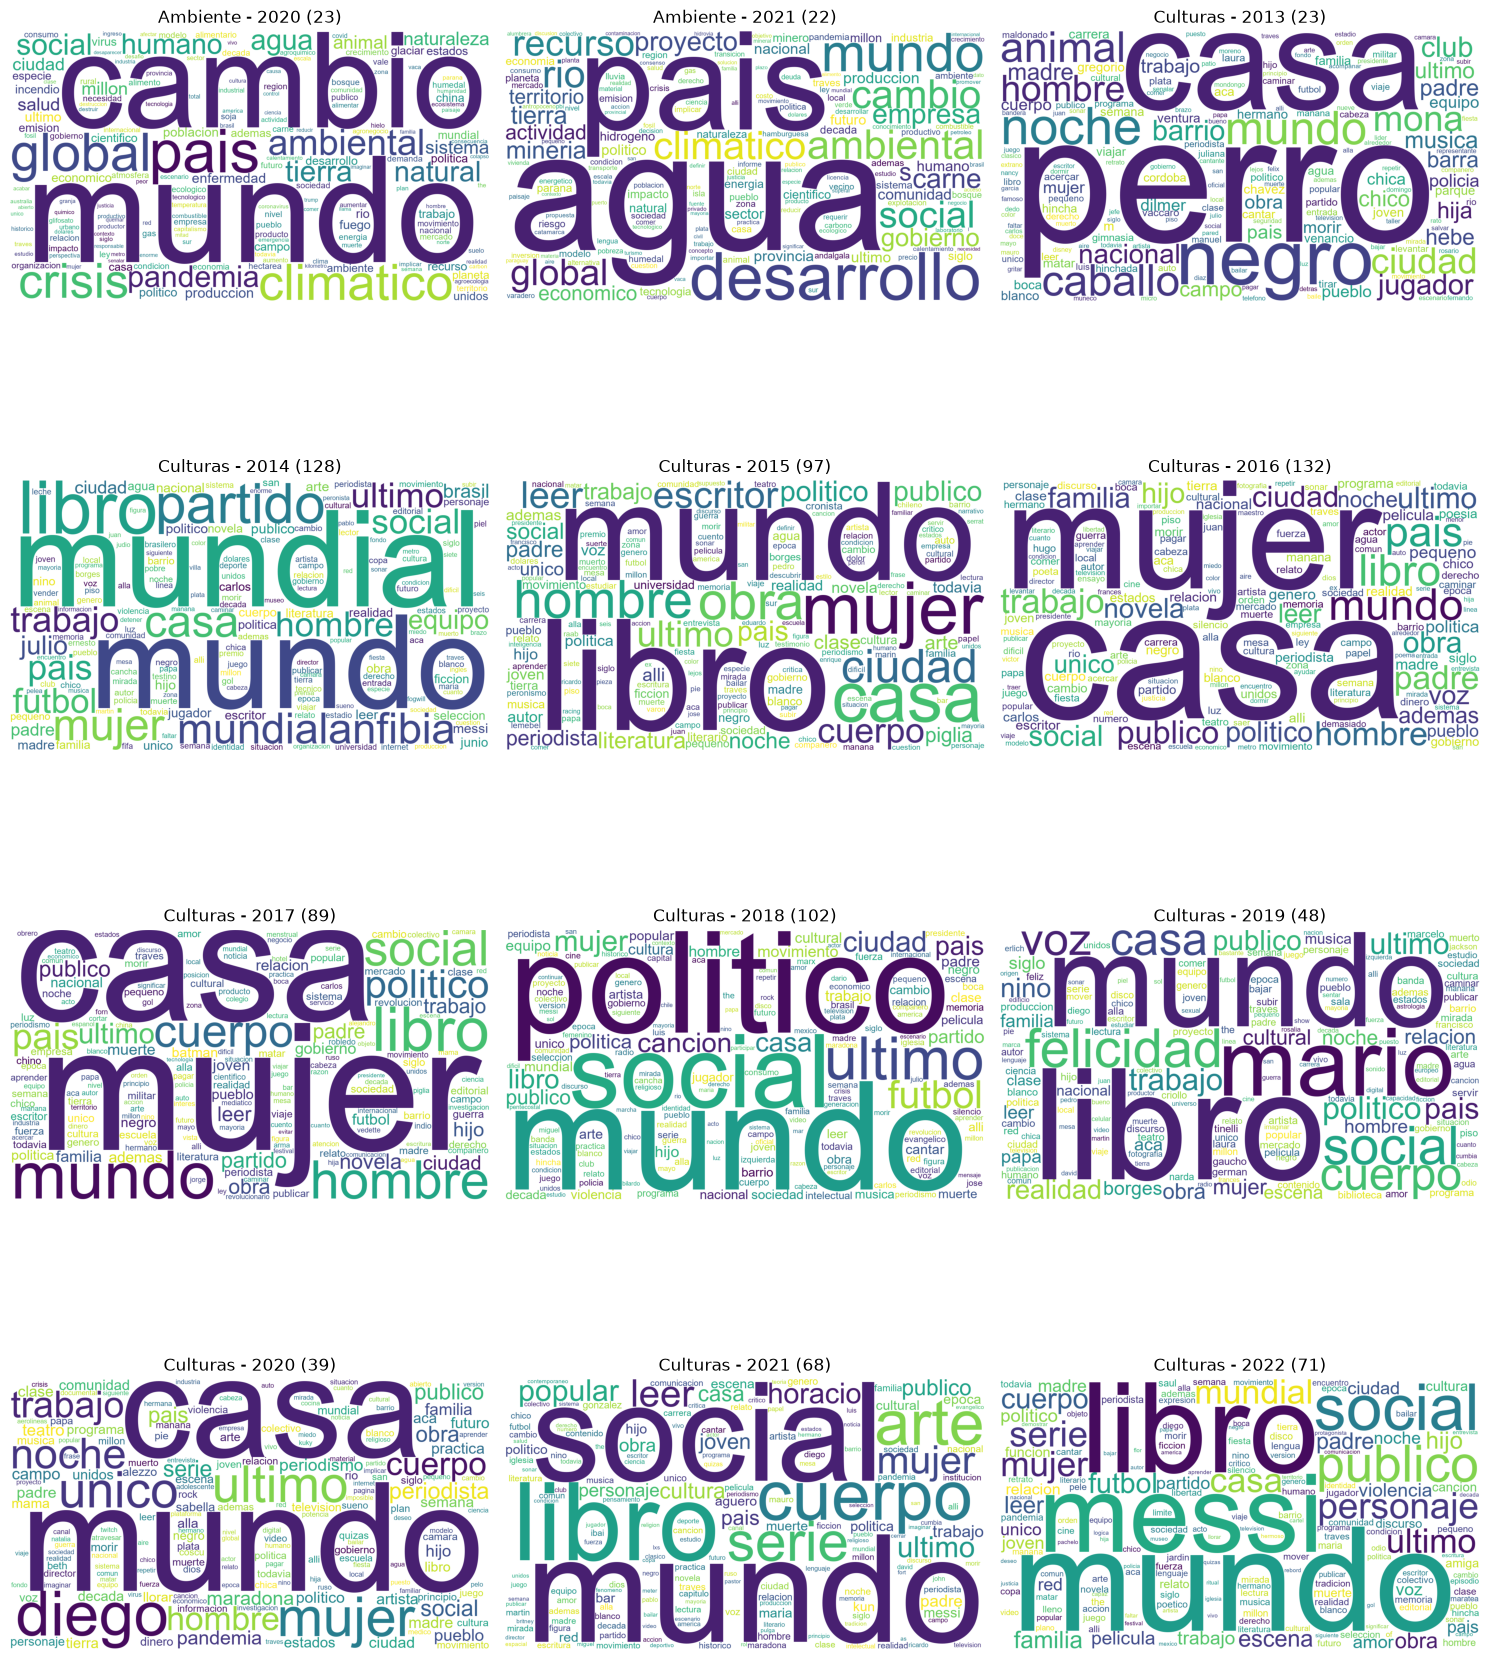

In [10]:

temporal_preview = temporal_wordcloud_index[temporal_wordcloud_index["enough_statistics"]].head(12)

if temporal_preview.empty:
    print("No hay ventanas categoría-período con estadística suficiente para previsualizar.")
else:
    n = len(temporal_preview)
    cols = 3
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4.8 * rows))
    axes = axes.flatten() if n > 1 else [axes]

    for ax, (_, row) in zip(axes, temporal_preview.iterrows()):
        image = plt.imread(PROJECT_ROOT / row["path"])
        ax.imshow(image)
        ax.set_title(f"{row['category']} - {row['period']} ({row['documents']})")
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


## 7. Bag of words por documento

La vectorización usa `document_text_final` normalizado. Los metadatos editoriales se guardan aparte para conservar una matriz puramente textual.


In [11]:
vectorizer = CountVectorizer(
    lowercase=False,
    strip_accents=None,
    stop_words=STOPWORDS_LIST,
    token_pattern=r"(?u)\b[a-záéíóúüñ][a-záéíóúüñ]{2,}\b",
    min_df=3,
    max_df=0.85,
    ngram_range=(1, 1),
)

bow_matrix = vectorizer.fit_transform(df["text_for_model"])
terms = vectorizer.get_feature_names_out()

bow_matrix.shape, len(terms)


((3555, 42846), 42846)

In [12]:
vocabulary = pd.DataFrame({
    "term_id": range(len(terms)),
    "term": terms,
    "document_frequency": (bow_matrix > 0).sum(axis=0).A1,
    "term_frequency": bow_matrix.sum(axis=0).A1,
}).sort_values(["term_frequency", "document_frequency", "term"], ascending=[False, False, True])

display(vocabulary.head(30))


,term_id,term,document_frequency,term_frequency
31568,31568,politico,2269,12372
37602,37602,social,2536,12229
27487,27487,mujer,1884,10692
29457,29457,pais,2417,9843
31563,31563,politica,2138,9611
19036,19036,gobierno,1859,9327
33003,33003,publico,2386,8656
27576,27576,mundo,2477,8512
6916,6916,casa,2009,7963
39998,39998,trabajo,2182,7376


In [13]:
attributes = df[["doc_id"] + ID_COLUMNS + ATTRIBUTE_COLUMNS].copy()
attributes["category_list"] = df["category"].map(split_categories)
attributes["word_count_model_text"] = df["text_for_model"].str.split().map(len)

document_index = attributes[["doc_id", "ID", "source_url", "title_text"]].copy()

sparse.save_npz(OUTPUT_DIR / "bow_document_term_matrix.npz", bow_matrix)
vocabulary.sort_values("term_id").to_csv(OUTPUT_DIR / "bow_vocabulary.csv", index=False)
attributes.to_csv(OUTPUT_DIR / "bow_document_attributes.csv", index=False)
document_index.to_csv(OUTPUT_DIR / "bow_document_index.csv", index=False)

with open(OUTPUT_DIR / "bow_vectorizer_config.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "source_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
            "text_column": TEXT_COLUMN,
            "attribute_columns": ATTRIBUTE_COLUMNS,
            "id_columns": ID_COLUMNS,
            "n_documents": int(bow_matrix.shape[0]),
            "n_terms": int(bow_matrix.shape[1]),
            "min_df": vectorizer.min_df,
            "max_df": vectorizer.max_df,
            "ngram_range": vectorizer.ngram_range,
            "token_pattern": vectorizer.token_pattern,
            "matrix_file": "bow_document_term_matrix.npz",
            "vocabulary_file": "bow_vocabulary.csv",
            "attributes_file": "bow_document_attributes.csv",
            "document_index_file": "bow_document_index.csv",
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

{
    "matrix": str((OUTPUT_DIR / "bow_document_term_matrix.npz").relative_to(PROJECT_ROOT)),
    "vocabulary": str((OUTPUT_DIR / "bow_vocabulary.csv").relative_to(PROJECT_ROOT)),
    "attributes": str((OUTPUT_DIR / "bow_document_attributes.csv").relative_to(PROJECT_ROOT)),
    "document_index": str((OUTPUT_DIR / "bow_document_index.csv").relative_to(PROJECT_ROOT)),
    "config": str((OUTPUT_DIR / "bow_vectorizer_config.json").relative_to(PROJECT_ROOT)),
}


{'matrix': 'data\\processed\\topic_modeling_lematizado\\bow_document_term_matrix.npz',
 'vocabulary': 'data\\processed\\topic_modeling_lematizado\\bow_vocabulary.csv',
 'attributes': 'data\\processed\\topic_modeling_lematizado\\bow_document_attributes.csv',
 'document_index': 'data\\processed\\topic_modeling_lematizado\\bow_document_index.csv',
 'config': 'data\\processed\\topic_modeling_lematizado\\bow_vectorizer_config.json'}

## 8. Cómo recargar la matriz después


In [14]:
loaded_matrix = sparse.load_npz(OUTPUT_DIR / "bow_document_term_matrix.npz")
loaded_vocab = pd.read_csv(OUTPUT_DIR / "bow_vocabulary.csv")
loaded_attributes = pd.read_csv(OUTPUT_DIR / "bow_document_attributes.csv")

loaded_matrix.shape, loaded_vocab.shape, loaded_attributes.shape


((3555, 42846), (42846, 4), (3555, 11))

Antes de la lematización:

```bash
((3557, 66923), (66923, 4), (3557, 11))
```

Paso de tener casi 70.000 palabras unicas a unas 43.000. Limpio casi 24.000 palabras redundantes.

In [19]:
### IMPORTAR ARCHIVOS PARA STREAMLIT

import shutil
from pathlib import Path

# Buscamos la raíz del proyecto
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Creamos la carpeta streamlit adentro del data principal
STREAMLIT_DIR = PROJECT_ROOT / "data" / "streamlit"
STREAMLIT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Guardar el conteo de categorías, el vocabulario y los atributos con post_date
category_counts.to_csv(STREAMLIT_DIR / "category_counts.csv", index=False)
vocabulary.to_csv(STREAMLIT_DIR / "bow_vocabulary.csv", index=False)
attributes.to_csv(STREAMLIT_DIR / "bow_document_attributes.csv", index=False)

# 2. Copiar físicamente las carpetas de imágenes a Streamlit
origen_wc_cat = PROJECT_ROOT / "outputs" / "wordclouds_by_category_lematizado"
destino_wc_cat = STREAMLIT_DIR / "wordclouds_by_category_lematizado"

origen_wc_temp = PROJECT_ROOT / "outputs" / "wordclouds_by_category_period"
destino_wc_temp = STREAMLIT_DIR / "wordclouds_by_category_period"

if origen_wc_cat.exists():
    shutil.copytree(origen_wc_cat, destino_wc_cat, dirs_exist_ok=True)
if origen_wc_temp.exists():
    shutil.copytree(origen_wc_temp, destino_wc_temp, dirs_exist_ok=True)

# 3. Actualizar las rutas en los DataFrames para que apunten a la nueva carpeta y guardar
# Reemplazamos "outputs" por "data/streamlit" en la columna "path" al vuelo
wordcloud_index_st = wordcloud_index.copy()
wordcloud_index_st["path"] = wordcloud_index_st["path"].str.replace("outputs", "data/streamlit", regex=False)
wordcloud_index_st.to_csv(STREAMLIT_DIR / "wordclouds_by_category_index.csv", index=False)

temporal_wordcloud_index_st = temporal_wordcloud_index.copy()
temporal_wordcloud_index_st["path"] = temporal_wordcloud_index_st["path"].str.replace("outputs", "data/streamlit", regex=False)
temporal_wordcloud_index_st.to_csv(STREAMLIT_DIR / "wordclouds_by_category_period_index.csv", index=False)

print(f"Todo guardado y centralizado correctamente en: {STREAMLIT_DIR}")

Todo guardado y centralizado correctamente en: C:\Trabajos\anfibia-unsam\data\streamlit
